In [1]:
import os
import sys


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import seaborn as sns
import random
from pathlib import Path
from numpy.linalg import norm
import datetime
import math
import multiprocess as mp
import time
import pickle
import pyarrow.feather as feather
from scipy.signal import savgol_filter
from sklearn.linear_model import LinearRegression
from scipy.signal import find_peaks
from sklearn.linear_model import TheilSenRegressor


In [2]:
# DATADIR = Path('lyaps')
SAVE_DIR = Path(Path.home(), 'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True
SET_JPARAM = False

lyaps_df_orig_dmso = feather.read_feather(Path(SAVE_DIR, 'lyaps_DMSO_cycdi_0_00.fea'))
int_dmso = feather.read_feather(Path(SAVE_DIR, 'mINT_DMSO_cycdi_0_00.fea'))
lyaps_df_orig_erl = feather.read_feather(Path(SAVE_DIR, 'lyaps_ERL_cycdi_0_00.fea'))
int_erl = feather.read_feather(Path(SAVE_DIR, 'mINT_ERL_cycdi_0_00.fea'))
lyaps_df_orig_low = feather.read_feather(Path(SAVE_DIR, 'lyaps_LOW_cycdi_0_00.fea'))
int_low = feather.read_feather(Path(SAVE_DIR, 'mINT_LOW_cycdi_0_00.fea'))

In [3]:
t = np.linspace(0, 1000, 1000001)
test = t[::2000]
len(test)

501

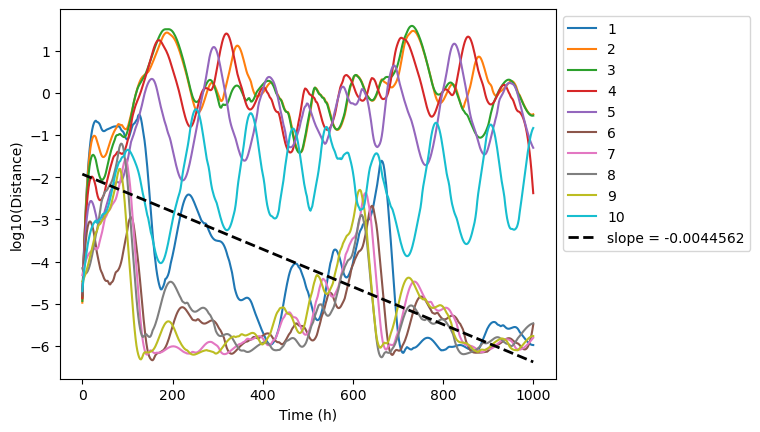

In [4]:
from scipy.stats import linregress


for ii in range(1,11):
    plt.plot(test, savgol_filter(lyaps_df_orig_low[ii][51],31,3), label=ii)

yvals = savgol_filter(lyaps_df_orig_low[1][51],31,3)
linfit = linregress(test,yvals)

plt.plot(test,linfit.slope*test+linfit.intercept, "k--", lw=2, label="slope = %g" % linfit.slope)

plt.xlabel('Time (h)')
plt.ylabel('log10(Distance)')
plt.legend(bbox_to_anchor=(1,1), loc='upper left')

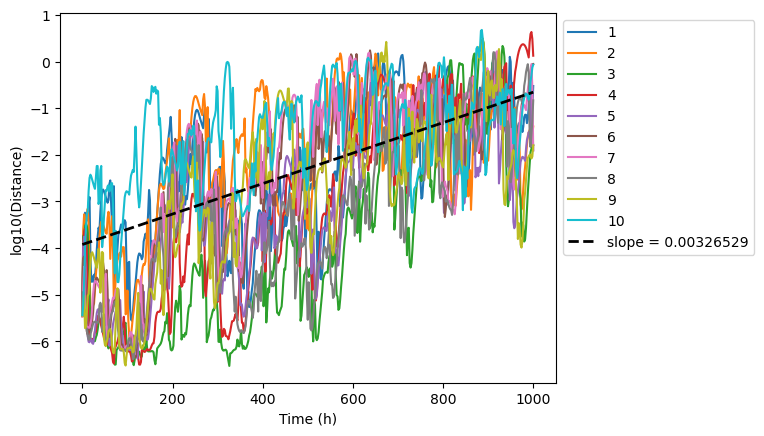

In [12]:
n = 100

for ii in range(1,11):
    plt.plot(test, lyaps_df_orig_low[ii][n], label=ii)

yvals = lyaps_df_orig_low[1][n]
linfit = linregress(test,yvals)

plt.plot(test,linfit.slope*test+linfit.intercept, "k--", lw=2, label="slope = %g" % linfit.slope)

plt.xlabel('Time (h)')
plt.ylabel('log10(Distance)')
plt.legend(bbox_to_anchor=(1,1), loc='upper left')

In [4]:
def get_avgs(lyaps_df):
    all_lyap_avgs = []
    for row in range(len(lyaps_df)):
        tmp_pos = lyaps_df.iloc[row,:]
        lyap_avgs=[]
        for posit in range(len(tmp_pos[1])):
            d=[]
            for i in range(len(tmp_pos)):
                i+=1
                d.append(tmp_pos[i][posit])
            lyap_avgs.append(sum(d)/len(d))   
        all_lyap_avgs.append(lyap_avgs)
    
    return all_lyap_avgs

def fit_lyap(lyap_trace):
    t = np.linspace(0, 1000, 501)
    max_t=np.argmax(lyap_trace)
    #np.argmin(results[1][1][tmp:])
    min_t = min(lyap_trace[max_t:])
    min_r = math.ceil(min_t*10)/10
    min_inds = [i for i,v in enumerate(lyap_trace) if v <= min_r]
    if min_inds[0] > max_t:
        coef = np.polyfit(t[max_t:min_inds[0]],lyap_trace[max_t:min_inds[0]],1)
        poly1d_fn = np.poly1d(coef)   
    else:
        coef = np.polyfit(t,lyap_trace,1)
        poly1d_fn = np.poly1d(coef)   
    return coef[0]

In [111]:
def _ols_slope(x, y):
    m, b = np.polyfit(x, y, 1)
    return float(m), float(b)

def fit_decay_slope_with_flat(
    trace,
    t=None,
    win=25,                 # window length for local slope estimates
    step=1,                 # slide step
    slope_thresh=4e-6,      # |slope| threshold to call a window "flat"
    std_thresh=None,        # low-variance gate (None to disable)
    consec_windows=5,       # require this many consecutive flat windows
    min_span=5,             # min points from max->endpoint
    on_no_flat="classify",  # "classify" -> return np.nan, "min" -> fall back to min after max
):
    """
    RAW-data fitter:
      1) Find global max.
      2) Scan forward in sliding windows for a sustained flat run (|slope|<thresh AND std<thresh).
      3) Fit OLS from max to the start of that run.
      4) If no flat run:
           - on_no_flat='classify' -> return NaN slope (non-convergent).
           - on_no_flat='min'      -> fallback to first min after max, then fit.
    Returns: slope, i_max, i_flat_start, i_flat_end, (m,b)
    """
    y = np.asarray(trace, dtype=float)
    n = y.size
    if n < max(7, win + 2):
        return np.nan, np.nan, np.nan, np.nan, (np.nan, np.nan)

    x = np.arange(n, dtype=float) if t is None else np.asarray(t, dtype=float)
    if x.shape != y.shape:
        raise ValueError("t must have same shape as trace")

    i_max = int(np.nanargmax(y))
    if i_max >= n - 2:
        return np.nan, i_max, np.nan, np.nan, (np.nan, np.nan)

    # Forward sliding windows AFTER the max
    W = int(min(max(5, win), n - (i_max + 1)))
    stp = int(max(1, step))

    win_starts, win_slopes, win_stds = [], [], []
    s = i_max + 1
    while s + W <= n:
        xs = x[s:s+W]
        ys = y[s:s+W]
        if np.isfinite(ys).sum() >= max(5, int(0.8 * W)):
            m, _ = _ols_slope(xs, ys)  # robust options: Theil-Sen or RANSAC if desired
            win_starts.append(s)
            win_slopes.append(m)
            win_stds.append(float(np.nanstd(ys)))
        s += stp

    win_starts  = np.array(win_starts, dtype=int)
    win_slopes  = np.array(win_slopes, dtype=float)
    win_stds    = np.array(win_stds, dtype=float)

    i_flat_start = None
    i_flat_end = None

    if win_starts.size:
        flat_mask = np.abs(win_slopes) < float(slope_thresh)
        if std_thresh is not None:
            flat_mask &= (win_stds <= float(std_thresh))

        # First run of 'consec_windows' consecutive True windows
        run = 0; end_idx = None
        for idx, ok in enumerate(flat_mask):
            run = run + 1 if ok else 0
            if run >= consec_windows:
                end_idx = idx
                break
        if end_idx is not None:
            start_idx = end_idx - consec_windows + 1
            i_flat_start = int(win_starts[start_idx])      # start of first flat window
            i_flat_end   = int(win_starts[end_idx] + W)    # end (exclusive) of last flat window

    # If no flat segment detected
    if i_flat_start is None:
        if on_no_flat == "min":
            tail = y[i_max + 1:]
            if tail.size == 0 or not np.isfinite(tail).any():
                return np.nan, i_max, np.nan, np.nan, (np.nan, np.nan)
            i_min_rel = int(np.nanargmin(tail))
            i_flat_start = i_max + 1 + i_min_rel
            i_flat_end   = i_flat_start + 1
        else:
            # classify as non-convergent (e.g., your cyan trace)
            return np.nan, i_max, np.nan, np.nan, (np.nan, np.nan)

    if i_flat_start - i_max < min_span:
        return np.nan, i_max, i_flat_start, i_flat_end, (np.nan, np.nan)

    xs_fit = x[i_max:i_flat_start + 1]
    ys_fit = y[i_max:i_flat_start + 1]
    if xs_fit.size < 2 or not (np.isfinite(xs_fit).all() and np.isfinite(ys_fit).all()):
        return np.nan, i_max, i_flat_start, i_flat_end, (np.nan, np.nan)

    m, b = _ols_slope(xs_fit, ys_fit)
    return float(m), i_max, i_flat_start, i_flat_end, (float(m), float(b))

In [107]:
def slopes_per_cell(df, t):
    """
    Compute slope for each cell in the DataFrame.

    Parameters
    ----------
    df : pd.DataFrame
        Each cell contains a trace (array-like).

    Returns
    -------
    slopes_df : pd.DataFrame
        Same shape as df, with slope values (floats or np.nan).
    """
    def _slope_or_nan(cell):
        try:
            arr = np.asarray(cell, dtype=float).ravel()
            if arr.size < 5 or not np.isfinite(arr).any():
                return np.nan
            return fit_decay_slope_with_flat(arr, t=t)[0]
        except Exception:
            return np.nan

    slopes = {}
    for col in df.columns:
        slopes[col] = df[col].apply(_slope_or_nan)

    return pd.DataFrame(slopes, index=df.index)


def avg_row_slopes(slopes_df):
    """
    Compute row-wise average slopes from a slopes DataFrame.

    Parameters
    ----------
    slopes_df : pd.DataFrame
        Output of slopes_per_cell().

    Returns
    -------
    avg_series : pd.Series
        Average slope per row (ignores NaNs).
    """
    return slopes_df.mean(axis=1, skipna=True)

In [117]:
fit_decay_slope_with_flat(lyaps_df_orig_low[5][150],t=test,slope_thresh=4e-3)

(-0.03981384127012845, 2, 22, 51, (-0.03981384127012845, -4.325511406569799))

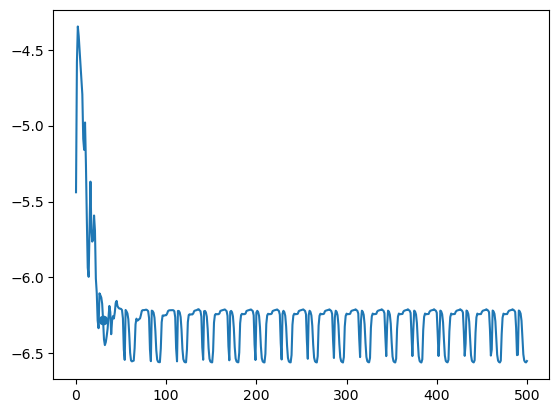

In [109]:
plt.plot(lyaps_df_orig_low[5][150], label=ii)
plt.scatter(30,lyaps_df_orig_low[5][150][30])

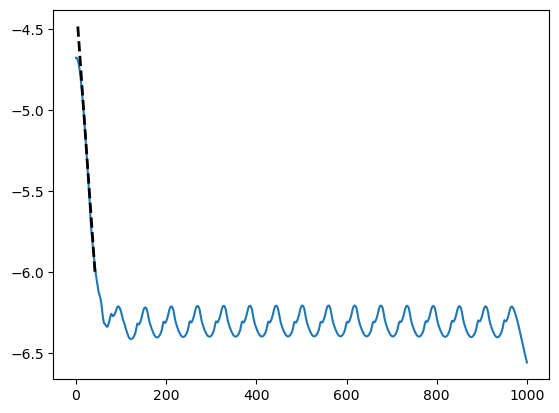

In [118]:
ii = 5
plt.plot(test, savgol_filter(lyaps_df_orig_low[ii][150],31,3), label=ii)
fit = fit_decay_slope_with_flat(lyaps_df_orig_low[ii][150],t=test,slope_thresh=4e-3)

# plt.plot(test,fit[0]*test+fit[1], "k--", lw=2)

plt.plot(test[fit[1]:fit[2]],fit[4][0]*test[fit[1]:fit[2]]+fit[4][1], "k--", lw=2)


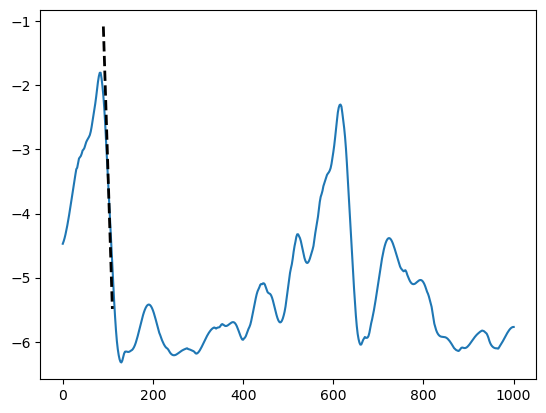

In [142]:
ii = 9
n=51
plt.plot(test, savgol_filter(lyaps_df_orig_low[ii][n],31,3), label=ii)
fit = fit_decay_slope_with_flat(lyaps_df_orig_low[ii][n],t=test,slope_thresh=4e-3)

# plt.plot(test,fit[0]*test+fit[1], "k--", lw=2)

plt.plot(test[fit[1]:fit[2]],fit[4][0]*test[fit[1]:fit[2]]+fit[4][1], "k--", lw=2)


In [61]:
fit

(-0.0005012576477542611,
 0,
 381,
 481,
 (-0.0005012576477542611, -6.058267718522855))

In [ ]:
for ii in range(1,11):
    plt.plot(test, savgol_filter(lyaps_df_orig_dmso[ii][100],31,3), label=ii)



plt.plot(test,linfit.slope*test+linfit.intercept, "k--", lw=2, label="slope = %g" % linfit.slope)

plt.xlabel('Time (h)')
plt.ylabel('log10(Distance)')
plt.legend(bbox_to_anchor=(1,1), loc='upper left')

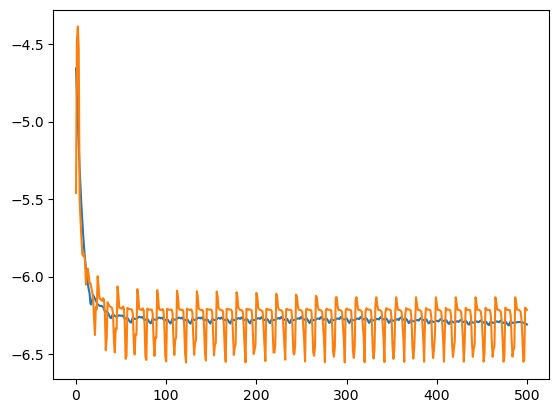

In [30]:
n = 5
plt.plot(savgol_filter(lyaps_df_orig_dmso[n][100],31,3))
plt.plot(lyaps_df_orig_dmso[n][100])

In [49]:
def remove_none(df):
    # Step 1: Apply dropna on each column and reset index
    cleaned_cols = []
    for col in df.columns:
        non_none_series = df[col].dropna().reset_index(drop=True)
        cleaned_cols.append(non_none_series)
    
    # Step 2: Concatenate cleaned columns
    # Each column now has length 151
    new_df = pd.concat(cleaned_cols, axis=1)
    
    # Optional: Set column names to match original
    new_df.columns = df.columns
    
    # Step 3: Final shape check
    # assert new_df.shape == (151, 5)

    return new_df


In [50]:
lyaps_df_orig_dmso = remove_none(lyaps_df_orig_dmso)
lyaps_df_orig_erl = remove_none(lyaps_df_orig_erl)
lyaps_df_orig_low = remove_none(lyaps_df_orig_low)

In [51]:
all_slopes_dmso = slopes_per_cell(lyaps_df_orig_dmso, test)
all_slopes_erl = slopes_per_cell(lyaps_df_orig_erl, test)
all_slopes_low = slopes_per_cell(lyaps_df_orig_low, test)

In [52]:
avg_dmso_slopes = avg_row_slopes(all_slopes_dmso)
avg_erl_slopes = avg_row_slopes(all_slopes_erl)
avg_low_slopes = avg_row_slopes(all_slopes_low)

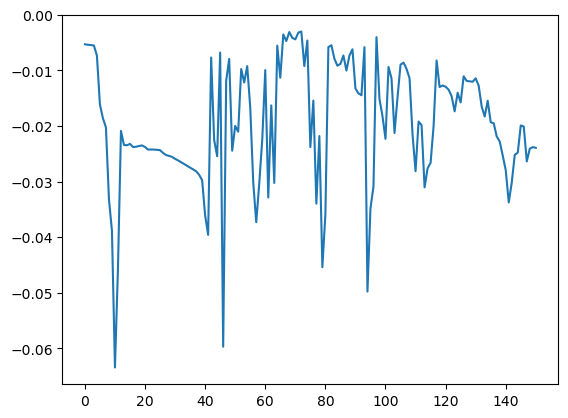

In [55]:
plt.plot(avg_low_slopes)

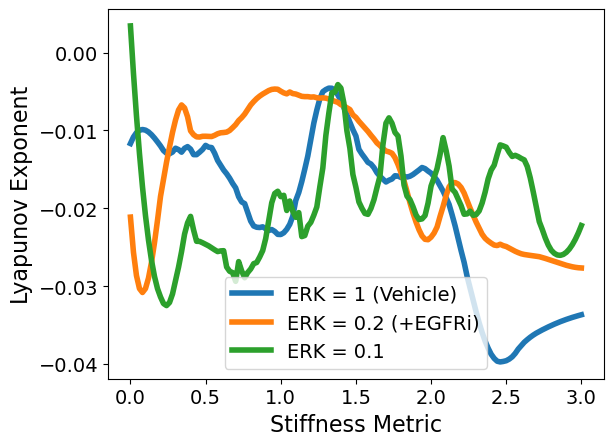

In [54]:
stiff = np.linspace(0,3,151)
lyap_dmso = savgol_filter(avg_dmso_slopes, 21, 3)
lyap_erl = savgol_filter(avg_erl_slopes, 21, 3)
lyap_low = savgol_filter(avg_low_slopes, 21, 3)
plt.plot(stiff,lyap_dmso, label='ERK = 1 (Vehicle)', lw=4)
plt.plot(stiff,lyap_erl, label='ERK = 0.2 (+EGFRi)', lw=4)
plt.plot(stiff,lyap_low, label='ERK = 0.1', lw=4)

plt.ylabel("Lyapunov Exponent", fontsize=16)
plt.xlabel("Stiffness Metric", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)




In [77]:
from scipy.interpolate import make_interp_spline

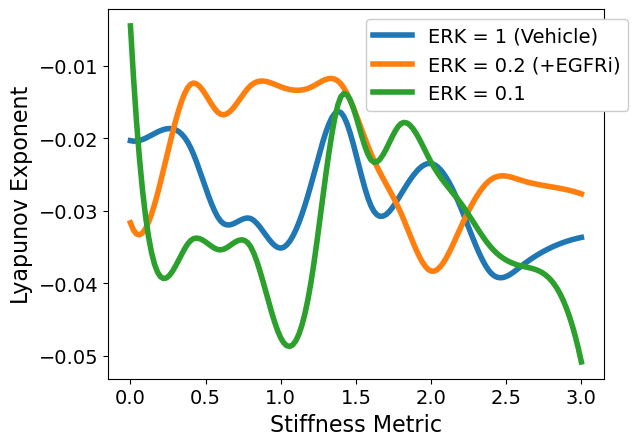

In [89]:
stiff = np.linspace(0,3,151)
lyap_dmso = savgol_filter(avg_dmso_slopes, 21, 3)
lyap_erl = savgol_filter(avg_erl_slopes, 21, 3)
lyap_low = savgol_filter(avg_low_slopes, 21, 3)

dmso_spline = make_interp_spline(stiff[::10],lyap_dmso[::10])
erl_spline = make_interp_spline(stiff[::10],lyap_erl[::10])
low_spline = make_interp_spline(stiff[::10],lyap_low[::10])


plt.plot(stiff,dmso_spline(stiff), lw=4, label='ERK = 1 (Vehicle)')
plt.plot(stiff,erl_spline(stiff), lw=4, label='ERK = 0.2 (+EGFRi)')
plt.plot(stiff,low_spline(stiff), lw=4, label='ERK = 0.1')
# plt.plot(stiff[::10],lyap_dmso[::10], label='ERK = 1 (Vehicle)', lw=4)
# plt.plot(stiff[::5],lyap_erl[::5], label='ERK = 0.2 (+EGFRi)', lw=4)
# plt.plot(stiff[::5],lyap_low[::5], label='ERK = 0.1', lw=4)

plt.ylabel("Lyapunov Exponent", fontsize=16)
plt.xlabel("Stiffness Metric", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14, bbox_to_anchor=(0.5,1), loc="upper left", framealpha=1)

In [73]:
stiff[::5]

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
       1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2, 2.3, 2.4, 2.5,
       2.6, 2.7, 2.8, 2.9, 3. ])

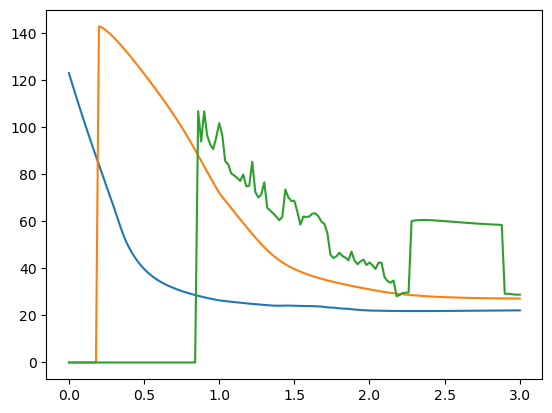

In [55]:
plt.plot(stiff,int_dmso[0], label='DMSO')
plt.plot(stiff,int_erl[0], label='ERL')
plt.plot(stiff,int_low[0], label='LOW')

In [64]:
if SET_JPARAM:
    lyap_erl_fn = Path(SAVE_DIR,'lyap_erl_PSO.csv')
    lyap_dmso_fn = Path(SAVE_DIR,'lyap_dmso_PSO.csv')
else:
    lyap_erl_fn = Path(SAVE_DIR,'lyap_erl.csv')
    lyap_dmso_fn = Path(SAVE_DIR,'lyap_dmso.csv')
    lyap_low_fn = Path(SAVE_DIR,'lyap_low.csv')

if lyap_erl_fn.exists():
    print(f'{lyap_erl_fn} already exists.')
if not lyap_erl_fn.exists() or OVERWRITE:
    print(f'Writing file to {lyap_erl_fn}')
    np.savetxt(lyap_erl_fn, lyap_erl, delimiter=',')

if lyap_dmso_fn.exists():
    print(f'{lyap_dmso_fn} already exists.')
if not lyap_dmso_fn.exists() or OVERWRITE:
    print(f'Writing file to {lyap_dmso_fn}')
    np.savetxt(lyap_dmso_fn, lyap_dmso, delimiter=',')

if lyap_low_fn.exists():
    print(f'{lyap_low_fn} already exists.')
if not lyap_low_fn.exists() or OVERWRITE:
    print(f'Writing file to {lyap_low_fn}')
    np.savetxt(lyap_low_fn, lyap_low, delimiter=',')




C:\Users\olesk\ECM_mod_output\lyap_erl.csv already exists.
Writing file to C:\Users\olesk\ECM_mod_output\lyap_erl.csv
C:\Users\olesk\ECM_mod_output\lyap_dmso.csv already exists.
Writing file to C:\Users\olesk\ECM_mod_output\lyap_dmso.csv
Writing file to C:\Users\olesk\ECM_mod_output\lyap_low.csv


In [63]:
# DATADIR = Path('lyaps')
SAVE_DIR = Path(Path.home(), 'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True

int_dmso.to_csv(Path(SAVE_DIR,'dmso_IMT.csv'), index=False, header=False)
int_erl.to_csv(Path(SAVE_DIR,'erl_IMT.csv'), index=False, header=False)
int_low.to_csv(Path(SAVE_DIR,'low_IMT.csv'), index=False, header=False)
# lyaps_df_orig_erl = feather.read_feather(Path(SAVE_DIR, 'lyaps_ERL_cycdi_0_0_low.fea'))
# int_erl = feather.read_feather(Path(DATADIR, 'mIMT_erl.fea'))

In [8]:
all_lyap_avgs_orig_erl = get_avgs(lyaps_df_orig_erl)

In [9]:
all_lyap_fits_orig_erl = []
for lyap in all_lyap_avgs_orig_erl:
    all_lyap_fits_orig_erl.append(fit_lyap(lyap)) 

In [10]:
all_lyap_fits_orig_erl

[0.00022222879929003855, -0.005285481120568715]